# 1.2 — Sanity-Check the Interim Application Table

**Case**: Credit granting policy review for a Fintech client (Klavi).

**Goal of this notebook**: independently validate `data/interim/applications.parquet` against the
raw files before phase 2 relies on it. Everything is **re-derived from raw with fresh code** and
compared to the interim file — nothing from notebook 1.1's in-memory pipeline is trusted or reused.
Every check is assert-backed: the notebook fails loudly if any check breaks.

**Check families**:
1. **Reconciliation** (§2): row counts and keys match raw; pass-through columns untouched
2. **Join correctness / leakage** (§3): `REFERENCIA` = `DATA` wherever present; every reachable
   application matched; feature values faithful to the raw source rows
3. **Cleaning invariance** (§4): default rate per safra unchanged; no sentinel survived;
   cleaned columns differ from raw exactly on the sentinel rows
4. **Flag & dtype consistency** (§5): segment flags reproducible from raw; dtypes as specified

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

PROJECT_DIR = Path.cwd().parent
RAW_DIR = PROJECT_DIR / "data" / "raw"
APP_PATH = PROJECT_DIR / "data" / "interim" / "applications.parquet"


## 1. Load

Interim table plus both raw files, fresh. On raw, only the casts needed for comparison
(dates to datetime, `SAFRA` to int, `risco_aposta` to categorical string — same rule as 1.0/1.1).

In [2]:
app = pd.read_parquet(APP_PATH)

perf_raw = pd.read_parquet(RAW_DIR / "profile_case_credit.parquet")
feat_raw = pd.read_parquet(RAW_DIR / "transactions_case_credit.parquet")
feat_raw = feat_raw.drop(columns=[c for c in feat_raw.columns if c.startswith("__index_level")])

perf_raw["DATA"] = pd.to_datetime(perf_raw["DATA"])
perf_raw["SAFRA"] = perf_raw["SAFRA"].astype(int)
feat_raw["REFERENCIA"] = pd.to_datetime(feat_raw["REFERENCIA"])
feat_raw["risco_aposta"] = feat_raw["risco_aposta"].astype("Int64").astype("string")

print(f"app:  {app.shape[0]:,} rows x {app.shape[1]} cols")
print(f"perf: {perf_raw.shape[0]:,} rows x {perf_raw.shape[1]} cols")
print(f"feat: {feat_raw.shape[0]:,} rows x {feat_raw.shape[1]} cols")

app:  220,618 rows x 17 cols
perf: 220,618 rows x 5 cols
feat: 371,596 rows x 10 cols


**Key takeaway**: interim table (220,618 × 17) and both raw files loaded fresh — all comparisons
below run against raw, not against 1.1's objects.

## 2. Row & key reconciliation vs raw

The interim table must be exactly the raw application population: same row count, same
(`uuid`, `DATA`) key set, and the pass-through columns (`SAFRA`, `OVER30M2`, `STATUS`)
byte-identical — cleaning must never touch the target or the decision status.

In [3]:
# same rows, same keys
assert len(app) == len(perf_raw), f"row count: app {len(app):,} vs raw {len(perf_raw):,}"
assert not app.duplicated(subset=["uuid", "DATA"]).any(), "uuid + DATA not unique in app"

app_keys = set(map(tuple, app[["uuid", "DATA"]].itertuples(index=False)))
raw_keys = set(map(tuple, perf_raw[["uuid", "DATA"]].itertuples(index=False)))
assert app_keys == raw_keys, f"key sets differ: {len(app_keys ^ raw_keys):,} mismatched pairs"

# pass-through columns identical row-by-row (align on the key)
a = app.set_index(["uuid", "DATA"]).sort_index()
p = perf_raw.set_index(["uuid", "DATA"]).sort_index()
assert (a["SAFRA"] == p["SAFRA"]).all(), "SAFRA altered"
assert (a["STATUS"] == p["STATUS"]).all(), "STATUS altered"
same_target = (a["OVER30M2"] == p["OVER30M2"]) | (a["OVER30M2"].isna() & p["OVER30M2"].isna())
assert same_target.all(), "OVER30M2 altered"

print(f"rows: {len(app):,} == raw  |  key sets identical  |  SAFRA / STATUS / OVER30M2 untouched")

rows: 220,618 == raw  |  key sets identical  |  SAFRA / STATUS / OVER30M2 untouched


**Key takeaway**: the interim table is exactly the raw application population — 220,618 rows,
identical (`uuid`, `DATA`) key set, and `SAFRA` / `STATUS` / `OVER30M2` pass through unaltered.

## 3. Join correctness & leakage re-check

Re-derive the application-date join from raw with fresh code (`df_raw`, sentinels **not** cleaned)
and check the interim table against it: snapshot dates equal application dates, every reachable
application matched, and the untouched feature columns carry exactly the raw source values.

In [4]:
# independent re-derivation from raw: exact-date left join
df_raw = perf_raw.merge(
    feat_raw,
    left_on=["uuid", "DATA"], right_on=["uuid", "REFERENCIA"],
    how="left",
).set_index(["uuid", "DATA"]).sort_index()

matched = a["REFERENCIA"].notna()

# no future / stale info: snapshot date == application date wherever present
assert (a.loc[matched, "REFERENCIA"] == a.loc[matched].index.get_level_values("DATA")).all(), \
    "snapshot date != application date"

# completeness: the join reached every application whose uuid has any snapshot
n_reachable = perf_raw["uuid"].isin(feat_raw["uuid"]).sum()
assert matched.sum() == n_reachable, f"matched {matched.sum():,} vs reachable {n_reachable:,}"
assert matched.equals(df_raw["REFERENCIA"].notna()), "matched rows differ from raw re-derivation"

# faithfulness: untouched feature columns equal the raw source values (NaN-aware)
untouched = ["score_klavi_2", "classe_social", "regiao", "Renda", "risco_aposta", "Capacidade Financeira"]
for col in untouched:
    same = (a[col] == df_raw[col]) | (a[col].isna() & df_raw[col].isna())
    assert same.all(), f"{col}: {(~same).sum():,} rows differ from raw"

print(f"matched: {matched.sum():,} of {len(a):,} ({matched.mean():.1%}) == all reachable applications")
print(f"untouched columns faithful to raw: {', '.join(untouched)}")

matched: 114,689 of 220,618 (52.0%) == all reachable applications
untouched columns faithful to raw: score_klavi_2, classe_social, regiao, Renda, risco_aposta, Capacidade Financeira


**Key takeaway**: the join is faithful and leakage-free — `REFERENCIA` = `DATA` on all 114,689
matched rows (52.0%), the match set equals exactly the applications whose `uuid` has a snapshot,
and all six untouched feature columns are value-identical to their raw source rows.

## 4. Cleaning invariance

Cleaning must have changed **precisely** what 1.1 claimed and nothing else: per-safra default
rates identical to raw (the visual proof below), no sentinel surviving anywhere, and the two
cleaned columns differing from raw exactly on the sentinel rows.

per-safra default rates identical  |  overall: 10.30%


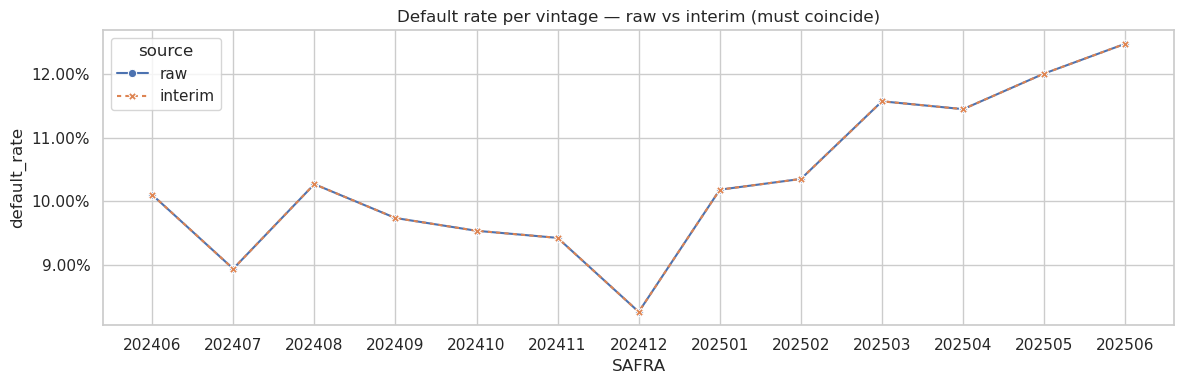

In [5]:
# default rate per safra: raw vs interim must coincide exactly
rate_raw = perf_raw.groupby("SAFRA")["OVER30M2"].mean()
rate_app = app.groupby("SAFRA")["OVER30M2"].mean()
pd.testing.assert_series_equal(rate_raw, rate_app)
print(f"per-safra default rates identical  |  overall: {app['OVER30M2'].mean():.2%}")

plot_df = pd.concat([
    rate_raw.rename("default_rate").reset_index().assign(source="raw"),
    rate_app.rename("default_rate").reset_index().assign(source="interim"),
])
plot_df["SAFRA"] = plot_df["SAFRA"].astype(str)

fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(data=plot_df, x="SAFRA", y="default_rate", hue="source", style="source",
             markers={"raw": "o", "interim": "X"}, dashes={"raw": "", "interim": (2, 2)}, ax=ax)
ax.set_title("Default rate per vintage — raw vs interim (must coincide)")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

In [6]:
# no sentinel survived, in any column
for col in app.select_dtypes(include="number").columns:
    n = (app[col] == -999999).sum()
    assert n == 0, f"{col}: {n:,} numeric sentinels remain"
for col in app.columns[app.dtypes.astype(str).isin(["str", "string", "object"])]:
    n = (app[col].astype("string") == "-999999").sum()
    assert n == 0, f"{col}: {n:,} string sentinels remain"
assert app["score_klavi_1"].dropna().between(0, 100).all(), "score_klavi_1 outside [0, 100]"
print("no -999999 sentinel in any column; score_klavi_1 within [0, 100]")

no -999999 sentinel in any column; score_klavi_1 within [0, 100]


In [7]:
# cleaned columns differ from raw EXACTLY on the sentinel rows
sk1_sent = df_raw["score_klavi_1"].eq(-999999)
same_sk1 = (a["score_klavi_1"] == df_raw["score_klavi_1"]) | (a["score_klavi_1"].isna() & df_raw["score_klavi_1"].isna())
assert same_sk1[~sk1_sent].all(), "score_klavi_1 altered outside sentinel rows"
assert a.loc[sk1_sent, "score_klavi_1"].isna().all(), "score_klavi_1 sentinel row not NaN"

emp_sent = df_raw["status_empregaticio"].eq("-999999")
same_emp = (a["status_empregaticio"] == df_raw["status_empregaticio"]) | \
           (a["status_empregaticio"].isna() & df_raw["status_empregaticio"].isna())
assert same_emp[~emp_sent].all(), "status_empregaticio altered outside sentinel rows"
assert a.loc[emp_sent, "status_empregaticio"].isna().all(), "status_empregaticio sentinel row not NaN"

print(f"score_klavi_1: NaN exactly on the {sk1_sent.sum():,} sentinel applications, untouched elsewhere")
print(f"status_empregaticio: NaN exactly on the {emp_sent.sum():,} sentinel applications, untouched elsewhere")

score_klavi_1: NaN exactly on the 676 sentinel applications, untouched elsewhere
status_empregaticio: NaN exactly on the 1,247 sentinel applications, untouched elsewhere


**Key takeaway**: cleaning changed precisely what it claimed — per-safra default rates coincide
exactly with raw (overall 10.30%), no `-999999` survives in any column, and the two cleaned
columns differ from raw only on their sentinel applications.

## 5. Flag & dtype consistency

The derived columns must be reproducible from raw: `has_snapshot` / `has_open_finance` from
their defining columns, `flag_capacidade_extrema` from the p0.1 cutoff re-derived on raw feat,
segment sizes matching 1.1, and dtypes as specified.

In [8]:
assert app["has_snapshot"].equals(app["REFERENCIA"].notna()), "has_snapshot inconsistent"
assert app["has_open_finance"].equals(app["Renda"].notna()), "has_open_finance inconsistent"

# flag_capacidade_extrema: null where no snapshot; else CF < p0.1 cutoff re-derived from raw feat
cutoff = feat_raw["Capacidade Financeira"].quantile(0.001)
flag = app["flag_capacidade_extrema"]
assert flag[~app["has_snapshot"]].isna().all(), "flag set on rows without snapshot"
expected_flag = app.loc[app["has_snapshot"], "Capacidade Financeira"] < cutoff
assert (flag[app["has_snapshot"]].astype(bool) == expected_flag).all(), "flag mismatch vs re-derived cutoff"
print(f"flags consistent  |  CF extreme cutoff (p0.1 of raw feat): {cutoff:,.0f}  |  flagged: {(flag == True).sum():,}")

# segment sizes match 1.1
segments = pd.Series(
    np.select(
        [~app["has_snapshot"], ~app["has_open_finance"]],
        ["no snapshot", "snapshot, no open finance"],
        default="snapshot + open finance",
    )
).value_counts()
expected_segments = {"no snapshot": 105_929, "snapshot, no open finance": 104_855,
                     "snapshot + open finance": 9_834}
assert segments.to_dict() == expected_segments, f"segment sizes changed: {segments.to_dict()}"
print(segments.to_frame("n").assign(pct=lambda t: (t["n"] / len(app) * 100).round(1)))

flags consistent  |  CF extreme cutoff (p0.1 of raw feat): -12,414  |  flagged: 121
                                n   pct
no snapshot                105929  48.0
snapshot, no open finance  104855  47.5
snapshot + open finance      9834   4.5


In [9]:
expected_dtypes = {
    "uuid": "str", "DATA": "datetime64[us]", "SAFRA": "int64", "OVER30M2": "float64",
    "STATUS": "str", "REFERENCIA": "datetime64[us]", "score_klavi_1": "float64",
    "score_klavi_2": "float64", "classe_social": "str", "status_empregaticio": "str",
    "regiao": "str", "Renda": "float64", "risco_aposta": "string",
    "Capacidade Financeira": "float64", "flag_capacidade_extrema": "object",
    "has_snapshot": "bool", "has_open_finance": "bool",
}
actual = dict(app.dtypes.astype(str))
assert actual == expected_dtypes, {k: (v, actual.get(k)) for k, v in expected_dtypes.items() if actual.get(k) != v}
print("dtypes as specified (flag_capacidade_extrema is object: True/False/None — null when no snapshot)")

dtypes as specified (flag_capacidade_extrema is object: True/False/None — null when no snapshot)


**Key takeaway**: all derived columns are reproducible from raw — flags consistent with their
defining columns, `flag_capacidade_extrema` matches the re-derived p0.1 cutoff (121 flagged
applications), segment sizes identical to 1.1 (105,929 / 104,855 / 9,834), dtypes as specified.

## 6. Key takeaways & general findings

**Key takeaways per section**

1. **§1 Load** — interim table and raw files loaded fresh; every check re-derives from raw with independent code, nothing reused from 1.1.
2. **§2 Reconciliation** — 220,618 rows, (`uuid`, `DATA`) key set identical to raw perf; `SAFRA` / `STATUS` / `OVER30M2` pass through byte-identical.
3. **§3 Join** — `REFERENCIA` = `DATA` on all 114,689 matched rows (52.0%); the match set equals exactly the applications whose `uuid` has a snapshot; all six untouched feature columns value-identical to their raw source rows.
4. **§4 Cleaning** — per-safra default rates coincide exactly with raw (overall 10.30%); no `-999999` anywhere; `score_klavi_1` and `status_empregaticio` differ from raw only on their sentinel applications.
5. **§5 Flags & dtypes** — flags reproducible from raw (`flag_capacidade_extrema` re-derived cutoff matches, 121 flagged); segments 105,929 / 104,855 / 9,834 as in 1.1; dtypes as specified.

**General findings**

- **The interim table is validated for phase 2**: it is exactly the raw application population, joined without leakage, cleaned surgically (sentinels only), with reproducible derived columns. No discrepancy found.
- One representational note: `flag_capacidade_extrema` is three-valued (True / False / None-when-no-snapshot) and stored as object — phase 2 should treat it alongside `has_snapshot`, not as a plain boolean.
- Phase 1 is complete; next is **2.0 univariate signal** (IV/WoE, default rate by decile, separation plots) on this table.